<table><tr>
<td style="border:none">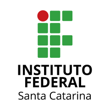</td>
<td style="border:none">
<h1 style="color:#54A021;margin-bottom:0">Laboratório 16-QAM — Simulação de ponta a ponta</h1>
<b>SCM203405 – Sistemas de Comunicação</b><br>
Superior em Eletrônica Industrial – IFSC Florianópolis
</td></tr></table>

---

## Como funciona esta atividade

Todo o código do transmissor, do canal e do receptor **já está implementado** neste notebook. O seu trabalho não é programar, e sim **observar, prever e explicar** o que acontece com o sinal em cada bloco da cadeia 16-QAM:

```
bits ─► S/P ─► LOOK-UP TABLE (Gray) ─► × portadoras ─► Σ ─► canal AWGN ─► correlatores ─► decisão ─► mapeamento reverso ─► bits
```

Três coisas tornam este laboratório **individual**:

1. **Seus parâmetros são gerados a partir da sua matrícula** (sequência de bits, frequência da portadora e Eb/N0 de referência). Dois colegas nunca terão os mesmos gráficos, nem os mesmos números para comentar — e as respostas devem citar os **seus** valores.
2. **Em alguns pontos você deve fazer uma previsão à mão *antes* de executar a célula** (marcados com ✋). Fotografe ou digitalize essa folha de rascunho e entregue junto — ela vale nota mesmo que a previsão esteja errada, desde que você comente a diferença depois.
3. **Uso de IA é permitido**, como você usaria um livro ou um colega. Mas ele deve ser registrado no **Log de uso de IA** ao final (que prompt usou, o que aproveitou, o que precisou corrigir), como se fosse uma citação de fonte.

As perguntas a responder estão nos blocos **🔎 Análise**. Responda nas células **✍️ Resposta** logo abaixo de cada uma, com suas palavras.

## 0. Configuração e parâmetros individuais

Substitua `MATRICULA` pelo seu número de matrícula (somente dígitos) e execute as duas células abaixo.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# Paleta IFSC (mesma dos slides da disciplina)
VERDE, VERDE_CLARO, CINZA = '#54A021', '#90C226', '#2C3C43'
LARANJA, VERMELHO, AMARELO, AZUL = '#E76618', '#C42F1A', '#E6B91E', '#1F6FB2'

plt.rcParams.update({
    'figure.figsize': (12, 3.5), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.titleweight': 'bold', 'axes.titlecolor': VERDE, 'font.size': 10,
})

def Qfunc(x):
    """Função Q gaussiana."""
    return 0.5 * erfc(x / np.sqrt(2))

In [ ]:
MATRICULA = 0          # <<<<< SUBSTITUA pela sua matrícula (apenas números)

if MATRICULA == 0:
    raise ValueError("Informe sua matrícula na variável MATRICULA antes de continuar.")

rng = np.random.default_rng(MATRICULA)

# ---------------- Parâmetros do sistema ----------------
M      = 16                     # ordem da modulação
k      = int(np.log2(M))        # bits por símbolo
N_BITS = 64                     # tamanho da sequência (conforme o roteiro)
Rs     = 1_000                  # taxa de símbolos [Bd]
T      = 1 / Rs                 # duração do símbolo [s]
Rb     = k * Rs                 # taxa de bits [bit/s]
Tb     = 1 / Rb                 # duração do bit [s]
fc     = Rs * int(rng.choice([3, 4, 5, 6]))     # portadora: múltiplo inteiro de Rs (individual)
fs     = 200_000                # frequência de amostragem da simulação [Hz]
dt     = 1 / fs
Ns     = int(round(T * fs))     # amostras por símbolo
E0     = 1.0                    # energia do símbolo de menor amplitude (escala da constelação)
EBN0_REF_DB = int(rng.choice([6, 8, 10, 12]))   # Eb/N0 de referência (individual)

bits_tx = rng.integers(0, 2, N_BITS)

print(f"Matrícula ............ {MATRICULA}")
print(f"Rs = {Rs} Bd   |  T = {T*1e3:.1f} ms  |  Rb = {Rb} bit/s  |  Tb = {Tb*1e3:.2f} ms")
print(f"fc = {fc/1e3:.0f} kHz  ({fc//Rs} ciclos de portadora por símbolo)")
print(f"fs = {fs/1e3:.0f} kHz  |  {Ns} amostras por símbolo")
print(f"Eb/N0 de referência .. {EBN0_REF_DB} dB")
print("Bits a transmitir:")
print(' '.join(''.join(map(str, bits_tx[i:i+4])) for i in range(0, N_BITS, 4)))

> **Anote** os seus valores de `fc`, `Eb/N0 de referência` e os **4 primeiros grupos de 4 bits** — você vai precisar deles nas previsões à mão.

---
# PARTE 1 — Modulador 16-QAM

Estrutura do modulador (do roteiro):

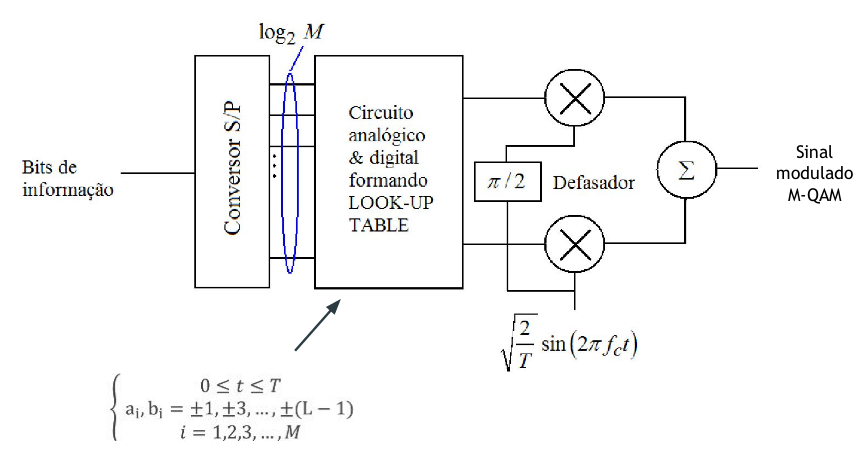

### Equação do sinal modulado

**Forma geral (um símbolo, $0 \le t \le T$):**

$$s_i(t) = \sqrt{\tfrac{2E_0}{T}}\,a_i\cos(2\pi f_c t) + \sqrt{\tfrac{2E_0}{T}}\,b_i\sin(2\pi f_c t)$$

**Forma em base ortonormal:** com $\psi_1(t)=\sqrt{2/T}\cos(2\pi f_c t)$ e $\psi_2(t)=\sqrt{2/T}\sin(2\pi f_c t)$,

$$s_i(t) = \sqrt{E_0}\,a_i\,\psi_1(t) + \sqrt{E_0}\,b_i\,\psi_2(t)$$

**Caso particular — 16-QAM quadrada ($L=4$):** $a_i, b_i \in \{\pm1, \pm3\}$, energia do símbolo $E_i = E_0(a_i^2+b_i^2)$, energia média $E_s = 10E_0$ e $E_b = E_s/4 = 2{,}5\,E_0$.

**Interpretação geométrica:** cada símbolo é um ponto $(a_i, b_i)$ no plano I×Q; a distância à origem fixa a amplitude da senoide transmitida e o ângulo fixa sua fase. 16-QAM é, portanto, modulação simultânea de amplitude **e** fase.

Nesta simulação usamos $E_0 = 1$, de modo que as coordenadas da tabela abaixo são diretamente os valores de I e Q.

## 1.1 Sequência de bits no tempo e na frequência

O sinal de bits é representado como pulsos retangulares de duração $T_b$. Mostramos a versão **unipolar** (0/1, como sai de um circuito lógico) e a **polar** (±1).

In [ ]:
def espectro(x, fs, nfft=None, ref=None):
    """Densidade espectral estimada (periodograma) em dB.
    Normaliza pelo pico do próprio sinal, ou por 'ref' (pico de outro sinal) se fornecido."""
    nfft = nfft or 16 * 2**int(np.ceil(np.log2(len(x))))
    X = np.fft.fftshift(np.fft.fft(x, nfft))
    f = np.fft.fftshift(np.fft.fftfreq(nfft, 1/fs))
    P = np.abs(X)**2
    return f, 10*np.log10(P / (ref if ref is not None else P.max()) + 1e-12), P.max()

Nb = int(round(Tb * fs))                       # amostras por bit
t_bits   = np.arange(N_BITS * Nb) * dt
b_unip   = np.repeat(bits_tx, Nb).astype(float)
b_polar  = 2*b_unip - 1

fig, ax = plt.subplots(1, 1, figsize=(12, 2.8))
ax.step(np.r_[t_bits, N_BITS*Tb]*1e3, np.r_[b_unip, b_unip[-1]], where='post', color=VERDE, lw=1.8)
for i in range(0, N_BITS + 1, 4):
    ax.axvline(i*Tb*1e3, color=CINZA, ls=':', lw=0.8)
for i, b in enumerate(bits_tx):
    ax.text((i + 0.5)*Tb*1e3, 1.12, str(b), ha='center', fontsize=7, color=CINZA)
ax.set_ylim(-0.2, 1.35); ax.set_xlabel('t [ms]'); ax.set_ylabel('bit')
ax.set_title('Sequência de bits no tempo (linhas pontilhadas = grupos de 4 bits → 1 símbolo)')
plt.tight_layout(); plt.show()

f, Pp, ref_polar = espectro(b_polar, fs)
_, Pu, _ = espectro(b_unip, fs, ref=ref_polar)     # mesma referência: compara níveis absolutos
teo = 10*np.log10(np.sinc(f*Tb)**2 + 1e-12)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(f/1e3, Pu, color=LARANJA, lw=1, alpha=0.8, label='unipolar (0/1)')
ax.plot(f/1e3, Pp, color=VERDE, lw=1, alpha=0.9, label='polar (±1)')
ax.plot(f/1e3, teo, 'k--', lw=1, label=r'envoltória teórica sinc$^2(fT_b)$')
for m in range(1, 5):
    ax.axvline(m*Rb/1e3, color=VERMELHO, ls=':', lw=0.8)
    ax.axvline(-m*Rb/1e3, color=VERMELHO, ls=':', lw=0.8)
ax.set_xlim(-5*Rb/1e3, 5*Rb/1e3); ax.set_ylim(-50, 12)
ax.set_xlabel('f [kHz]'); ax.set_ylabel('dB (ref.: pico do polar)')
ax.set_title(f'Espectro da sequência de bits (linhas vermelhas em múltiplos de Rb = {Rb/1e3:.0f} kHz)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

### 🔎 Análise 1.1
1. Onde ficam os nulos do espectro? Relacione com $T_b$ dos **seus** parâmetros.
2. As duas curvas estão na mesma referência. Por que a versão unipolar apresenta um pico em $f=0$ que a polar não apresenta, e por que o restante do espectro unipolar fica cerca de 6 dB abaixo do polar? Que consequência isso teria para transmitir esse sinal por um canal com acoplamento capacitivo (que bloqueia DC)?
3. O espectro de uma única sequência de 64 bits é "irregular" quando comparado à envoltória teórica. Por quê? O que você faria para obter uma curva mais próxima da teórica?

**✍️ Resposta 1.1:**

## 1.2 Conversor S/P e tabela de consulta (LOOK-UP TABLE) com código Gray

O conversor S/P apenas agrupa os bits de 4 em 4. Cada grupo é mapeado em um par $(a_i, b_i)$:

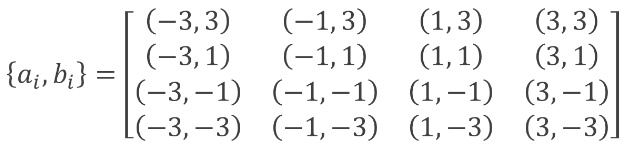

O mapeamento segue o **código Gray** do roteiro:

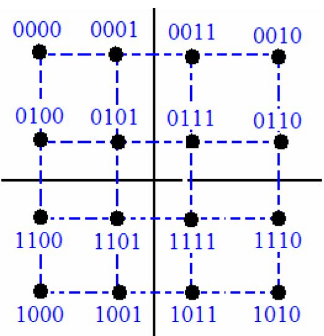

### ✋ Previsão à mão (faça ANTES de executar a próxima célula)
Usando a figura acima, escreva na sua folha de rascunho os pares $(a_i, b_i)$ dos **4 primeiros símbolos** da sua sequência.

In [ ]:
# ---- Construção da LOOK-UP TABLE a partir da figura do código Gray ----
# Linha de cima (b = +3) da esquerda (a = -3) para a direita (a = +3), e assim por diante.
GRAY_GRID = [['0000', '0001', '0011', '0010'],    # b = +3
             ['0100', '0101', '0111', '0110'],    # b = +1
             ['1100', '1101', '1111', '1110'],    # b = -1
             ['1000', '1001', '1011', '1010']]    # b = -3
NIVEIS_A = [-3, -1, 1, 3]
NIVEIS_B = [3, 1, -1, -3]

LUT = {}          # '0110' -> (a, b)
for lin, b in enumerate(NIVEIS_B):
    for col, a in enumerate(NIVEIS_A):
        LUT[GRAY_GRID[lin][col]] = (a, b)
LUT_INV = {v: kbits for kbits, v in LUT.items()}          # (a, b) -> '0110'

CONSTELACAO = np.array([LUT[kb] for kb in sorted(LUT)], dtype=float)   # 16 x 2
ROTULOS     = sorted(LUT)

def conversor_SP(bits, k=4):
    return [''.join(map(str, bits[i:i+k])) for i in range(0, len(bits), k)]

def mapear(grupos):
    ab = np.array([LUT[g] for g in grupos], dtype=float)
    return ab[:, 0], ab[:, 1]

grupos_tx = conversor_SP(bits_tx)
a_tx, b_tx = mapear(grupos_tx)
N_SIMB = len(grupos_tx)

print("Símbolo | bits | (a_i, b_i) | energia E_i = a²+b²")
print("-"*50)
for i, (g, a, b) in enumerate(zip(grupos_tx, a_tx, b_tx)):
    print(f"  {i:2d}    | {g} | ({a:+.0f}, {b:+.0f})   | {a*a + b*b:.0f}")
print(f"\nEnergia média da sua sequência: {np.mean(a_tx**2 + b_tx**2):.2f}  (média teórica = 10)")

In [ ]:
def desenha_constelacao(ax, rotulos=True):
    ax.scatter(CONSTELACAO[:, 0], CONSTELACAO[:, 1], s=60, color=CINZA, zorder=3)
    if rotulos:
        for (a, b), lab in zip(CONSTELACAO, ROTULOS):
            ax.text(a, b + 0.35, lab, ha='center', color=AZUL, fontsize=9)
    for lim in (-2, 0, 2):                         # fronteiras de decisão
        ax.axvline(lim, color=VERDE_CLARO, ls='--', lw=0.9)
        ax.axhline(lim, color=VERDE_CLARO, ls='--', lw=0.9)
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect('equal')
    ax.set_xlabel('I  (coordenada sobre ψ₁)'); ax.set_ylabel('Q  (coordenada sobre ψ₂)')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
desenha_constelacao(ax)
usados = np.unique(np.c_[a_tx, b_tx], axis=0)
ax.scatter(usados[:, 0], usados[:, 1], s=180, facecolors='none', edgecolors=LARANJA, lw=2,
           label='símbolos presentes na sua sequência', zorder=4)
ax.set_title('Constelação 16-QAM com mapeamento Gray'); ax.legend(loc='lower center', fontsize=8,
           bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.show()

## 1.3 Sinais I(t) e Q(t) na saída da LOOK-UP TABLE

In [ ]:
t = np.arange(N_SIMB * Ns) * dt
I_t = np.repeat(a_tx, Ns)
Q_t = np.repeat(b_tx, Ns)

fig, axs = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True)
for ax, sig, nome, cor in [(axs[0], I_t, 'I(t) = a_i', VERDE), (axs[1], Q_t, 'Q(t) = b_i', LARANJA)]:
    ax.step(t*1e3, sig, where='post', color=cor, lw=1.8)
    ax.set_yticks([-3, -1, 1, 3]); ax.set_ylim(-4, 4); ax.set_ylabel(nome)
    for i in range(N_SIMB + 1):
        ax.axvline(i*T*1e3, color=CINZA, ls=':', lw=0.6)
for i, g in enumerate(grupos_tx):
    axs[0].text((i + 0.5)*T*1e3, 3.4, g, ha='center', fontsize=7, color=AZUL)
axs[0].set_title('Saída da LOOK-UP TABLE (rótulos = grupo de 4 bits de cada símbolo)')
axs[1].set_xlabel('t [ms]'); plt.tight_layout(); plt.show()

### 🔎 Análise 1.2 / 1.3
1. Compare sua previsão à mão com a tabela gerada. Acertou? Se errou, onde estava o engano?
2. Escolha dois símbolos **vizinhos** na constelação e dois símbolos **diagonais**. Quantos bits diferem em cada caso? Explique por que isso é vantajoso quando o ruído desloca o símbolo recebido.


**✍️ Resposta 1.2 / 1.3:**

## 1.4 Portadoras (funções-base) ψ₁(t) e ψ₂(t)

No diagrama, um único oscilador $\sqrt{2/T}\sin(2\pi f_c t)$ alimenta o ramo Q diretamente e, através do defasador de $\pi/2$, gera $\sqrt{2/T}\cos(2\pi f_c t)$ para o ramo I.

### ✋ Previsão à mão
Calcule à mão $\int_0^T \psi_1^2(t)\,dt$ e $\int_0^T \psi_1(t)\psi_2(t)\,dt$ supondo $f_c$ múltiplo inteiro de $1/T$. Depois compare com os valores numéricos abaixo.

In [ ]:
psi1 = np.sqrt(2/T) * np.cos(2*np.pi*fc*t)
psi2 = np.sqrt(2/T) * np.sin(2*np.pi*fc*t)

n_show = 2 * Ns
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t[:n_show]*1e3, psi1[:n_show], color=VERDE, label='ψ₁(t) = √(2/T)·cos(2πf_c t)')
ax.plot(t[:n_show]*1e3, psi2[:n_show], color=LARANJA, label='ψ₂(t) = √(2/T)·sin(2πf_c t)')
ax.axvline(T*1e3, color=CINZA, ls=':')
ax.set_xlabel('t [ms]'); ax.set_title(f'Funções-base nos 2 primeiros símbolos (f_c = {fc/1e3:.0f} kHz)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

E1  = np.sum(psi1[:Ns]**2) * dt
E2  = np.sum(psi2[:Ns]**2) * dt
P12 = np.sum(psi1[:Ns]*psi2[:Ns]) * dt
print(f"∫ψ₁² dt  = {E1:.6f}")
print(f"∫ψ₂² dt  = {E2:.6f}")
print(f"∫ψ₁ψ₂ dt = {P12:.2e}")

NameError: name 'np' is not defined

## 1.5 Sinal modulado s(t) — tempo e frequência

In [ ]:
ramo_I = np.sqrt(E0) * I_t * psi1
ramo_Q = np.sqrt(E0) * Q_t * psi2
s_t    = ramo_I + ramo_Q
envolt = np.sqrt(E0) * np.sqrt(2/T) * np.sqrt(I_t**2 + Q_t**2)

n_show = 6 * Ns
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axs[0].plot(t[:n_show]*1e3, ramo_I[:n_show], color=VERDE);   axs[0].set_ylabel('a_i·ψ₁(t)')
axs[0].set_ylim(-1.15*np.abs(ramo_I).max(), 1.7*np.abs(ramo_I).max())
axs[1].plot(t[:n_show]*1e3, ramo_Q[:n_show], color=LARANJA); axs[1].set_ylabel('b_i·ψ₂(t)')
axs[2].plot(t[:n_show]*1e3, s_t[:n_show], color=CINZA, lw=1)
axs[2].plot(t[:n_show]*1e3,  envolt[:n_show], color=VERMELHO, ls='--', lw=1, label='envoltória √(a²+b²)·√(2/T)')
axs[2].plot(t[:n_show]*1e3, -envolt[:n_show], color=VERMELHO, ls='--', lw=1)
axs[2].set_ylabel('s(t)'); axs[2].legend(loc='upper right', fontsize=8)
for ax in axs:
    for i in range(7):
        ax.axvline(i*T*1e3, color=CINZA, ls=':', lw=0.6)
for i in range(6):
    axs[0].text((i + 0.5)*T*1e3, axs[0].get_ylim()[1]*0.72, f'{grupos_tx[i]}\n({a_tx[i]:+.0f},{b_tx[i]:+.0f})',
                ha='center', fontsize=7, color=AZUL)
axs[0].set_title('Ramos em fase e em quadratura, e o sinal 16-QAM resultante (6 primeiros símbolos)')
axs[2].set_xlabel('t [ms]'); plt.tight_layout(); plt.show()

Es_med = np.mean([np.sum(s_t[i*Ns:(i+1)*Ns]**2)*dt for i in range(N_SIMB)])
print(f"Energia média por símbolo medida em s(t): {Es_med:.3f}   (compare com a média de a²+b² da sua sequência)")

f, Ps, _ = espectro(s_t, fs)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(f/1e3, Ps, color=VERDE, lw=1)
for x in (fc - Rs, fc, fc + Rs):
    ax.axvline(x/1e3, color=VERMELHO, ls=':', lw=1)
ax.set_xlim(0, (fc + 5*Rs)/1e3); ax.set_ylim(-50, 3)
ax.set_xlabel('f [kHz]'); ax.set_ylabel('dB (normalizado)')
ax.set_title(f'Espectro de s(t) — linhas em f_c e f_c ± Rs ({(fc-Rs)/1e3:.0f}, {fc/1e3:.0f}, {(fc+Rs)/1e3:.0f} kHz)')
plt.tight_layout(); plt.show()

### 🔎 Análise 1.4 / 1.5
1. Os valores numéricos de $\int\psi_1^2$ e $\int\psi_1\psi_2$ batem com sua previsão à mão? O que significa, fisicamente, $\int\psi_1\psi_2\,dt = 0$?
2. Escolha **um** símbolo da sua sequência e identifique no gráfico de $s(t)$ sua amplitude e sua fase. Confira com $\sqrt{a_i^2+b_i^2}$ e com $\operatorname{atan2}(b_i, a_i)$ (atenção à convenção de sinal do seno).
3. Qual é a largura de banda entre nulos do lóbulo principal de $s(t)$? Compare com a largura do lóbulo principal da sequência de bits polar (Parte 1.1). Quantas vezes mais estreito ficou? Justifique com $R_b$, $R_s$ e $k$.
4. Por que a energia medida em $s(t)$ é igual à média de $a_i^2+b_i^2$? Que propriedade das funções-base garante isso?

**✍️ Resposta 1.4 / 1.5:**

---
# PARTE 2 — Demodulador por correlação (canal ideal)

Estrutura do receptor (do roteiro):

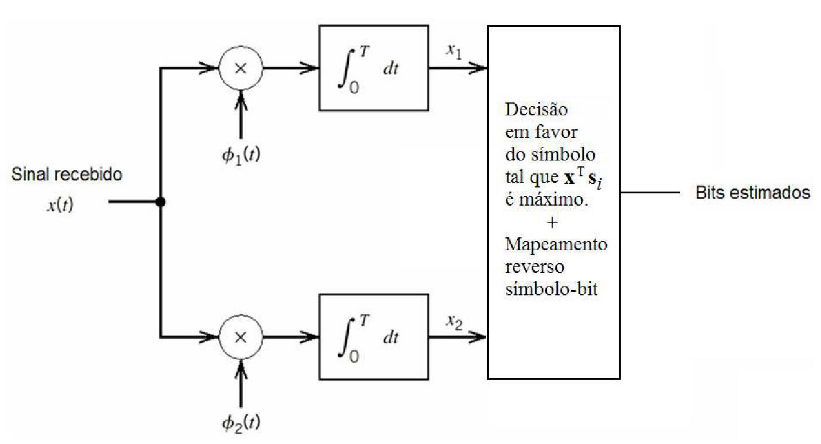

### Saída do correlator

**Forma geral:** $\displaystyle x_j = \int_0^T r(t)\,\psi_j(t)\,dt,\quad j=1,2$

**Canal ideal ($r = s_i$):** pela ortonormalidade, $x_1 = \sqrt{E_0}\,a_i$ e $x_2 = \sqrt{E_0}\,b_i$ — o correlator "projeta" o sinal recebido sobre cada eixo da constelação.

**Caso particular — canal AWGN (Parte 3):** $x_j = \sqrt{E_0}\,(a_i \text{ ou } b_i) + n_j$, com $n_j \sim \mathcal{N}(0, N_0/2)$ independentes.

**Interpretação:** o vetor $\mathbf{x} = (x_1, x_2)$ é o ponto onde o símbolo **chegou** na constelação; a decisão escolhe o ponto ideal **mais próximo** (mínima distância euclidiana).

O correlator é implementado como **integra-e-descarrega**: a integral cresce durante o símbolo, é amostrada em $t = T$ e zerada para o próximo símbolo.

In [ ]:
def correlator(r, psi, Ns, dt):
    """Integra-e-descarrega. Retorna (amostras no fim de cada símbolo, integral corrente)."""
    produto  = (r * psi).reshape(-1, Ns)
    corrente = np.cumsum(produto, axis=1) * dt
    return corrente[:, -1], corrente.ravel()

def decisao_min_distancia(x1, x2):
    """Escolhe, para cada (x1, x2), o ponto da constelação mais próximo."""
    x = np.c_[x1, x2] / np.sqrt(E0)
    d2 = ((x[:, None, :] - CONSTELACAO[None, :, :])**2).sum(axis=2)
    return CONSTELACAO[np.argmin(d2, axis=1)]

def mapeamento_reverso(simbolos):
    grupos = [LUT_INV[(int(a), int(b))] for a, b in simbolos]
    return np.array([int(c) for g in grupos for c in g]), grupos

def demodular(r):
    tt = np.arange(len(r)) * dt
    p1 = np.sqrt(2/T) * np.cos(2*np.pi*fc*tt)
    p2 = np.sqrt(2/T) * np.sin(2*np.pi*fc*tt)
    x1, c1 = correlator(r, p1, Ns, dt)
    x2, c2 = correlator(r, p2, Ns, dt)
    simb = decisao_min_distancia(x1, x2)
    bits, grupos = mapeamento_reverso(simb)
    return dict(x1=x1, x2=x2, c1=c1, c2=c2, simb=simb, bits=bits, grupos=grupos)

def plota_correlatores(res, n_simb=8, titulo=''):
    n = n_simb * Ns
    tt = np.arange(n) * dt * 1e3
    fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    for ax, c, x, nome, cor in [(axs[0], res['c1'], res['x1'], 'x₁ (ramo I)', VERDE),
                                (axs[1], res['c2'], res['x2'], 'x₂ (ramo Q)', LARANJA)]:
        ax.plot(tt, c[:n], color=cor, lw=1.4)
        ax.plot((np.arange(n_simb) + 1)*T*1e3, x[:n_simb], 'o', color=VERMELHO, ms=6,
                label='amostra em t = T (saída do correlator)')
        for lv in (-3, -1, 1, 3):
            ax.axhline(lv*np.sqrt(E0), color=CINZA, ls=':', lw=0.7)
        for i in range(n_simb + 1):
            ax.axvline(i*T*1e3, color=CINZA, ls=':', lw=0.5)
        ax.set_ylabel(nome); ax.set_ylim(-4.5, 4.5)
    axs[0].legend(loc='upper right', fontsize=8)
    axs[0].set_title(titulo or 'Integral corrente nos correlatores (integra-e-descarrega)')
    axs[1].set_xlabel('t [ms]'); plt.tight_layout(); plt.show()

def compara_bits(bits_rx, titulo=''):
    erros = np.flatnonzero(bits_rx != bits_tx)
    fig, ax = plt.subplots(figsize=(12, 2.6))
    ax.step(np.arange(N_BITS + 1), np.r_[bits_tx, bits_tx[-1]] + 1.4, where='post', color=VERDE, label='transmitido')
    ax.step(np.arange(N_BITS + 1), np.r_[bits_rx, bits_rx[-1]], where='post', color=LARANJA, label='demodulado')
    for e in erros:
        ax.axvspan(e, e + 1, color=VERMELHO, alpha=0.25)
    ax.set_yticks([0, 1, 1.4, 2.4]); ax.set_yticklabels(['0', '1', '0', '1'])
    ax.set_xlabel('índice do bit'); ax.legend(loc='upper right', fontsize=8, ncol=2)
    ax.set_title(titulo or f'Bits transmitidos × demodulados — {len(erros)} erro(s) (em vermelho)')
    plt.tight_layout(); plt.show()
    return erros

res_ideal = demodular(s_t)
plota_correlatores(res_ideal, titulo='Saída dos correlatores — canal ideal (8 primeiros símbolos)')

In [ ]:
print("Símb | x₁ (I)  | x₂ (Q)  | decisão | bits rx | bits tx")
print("-"*58)
for i in range(N_SIMB):
    a, b = res_ideal['simb'][i]
    print(f" {i:2d}  | {res_ideal['x1'][i]:+7.4f} | {res_ideal['x2'][i]:+7.4f} | ({a:+.0f},{b:+.0f}) "
          f"|  {res_ideal['grupos'][i]}   |  {grupos_tx[i]}")

print("\nOriginal  :", ' '.join(grupos_tx))
print("Demodulado:", ' '.join(res_ideal['grupos']))
erros = compara_bits(res_ideal['bits'], 'Canal ideal — bits transmitidos × demodulados')
print(f"Bits errados: {len(erros)} de {N_BITS}")

### 🔎 Análise 2
1. Por que só o valor no instante $t = T$ interessa? O que aconteceria se o receptor amostrasse em $t = T/2$? (Você pode testar alterando a função `correlator`.)
2. Explique, com suas palavras, as três etapas do receptor: correlação → decisão → mapeamento reverso. Cite um símbolo **da sua sequência** como exemplo, acompanhando-o pelas três etapas.

**✍️ Resposta 2:**

---
# PARTE 3 — Canal AWGN: o símbolo "sai do lugar"

O canal soma ruído branco gaussiano $w(t)$ de densidade espectral bilateral $N_0/2$:

$$r(t) = s(t) + w(t)$$

Você informa $E_b/N_0$ em dB. Como $E_b = 2{,}5\,E_0$ é fixo, o código calcula $N_0 = E_b / 10^{(E_b/N_0)_{dB}/10}$. Na simulação discreta, cada amostra de ruído tem variância $\sigma^2 = N_0/(2\,\Delta t)$, o que garante que, **na saída do correlator**, o ruído tenha variância $N_0/2$.

### ✋ Previsão à mão
Para o **seu** Eb/N0 de referência, calcule $N_0$ e o desvio-padrão esperado do ruído na saída do correlator, $\sqrt{N_0/2}$. Compare esse valor com a distância entre um ponto da constelação e a fronteira de decisão mais próxima (que vale 1). Com base nisso, você espera muitos ou poucos erros entre os 16 símbolos?

In [ ]:
Eb = 2.5 * E0

def canal_awgn(s, EbN0_dB, rng_canal):
    N0 = Eb / 10**(EbN0_dB / 10)
    sigma = np.sqrt(N0 / (2*dt))
    return s + sigma * rng_canal.standard_normal(len(s)), N0

def modular_aleatorio(n_simb, rng_local):
    """Gera n_simb símbolos aleatórios e o s(t) correspondente (para as nuvens e a curva de BER)."""
    bits = rng_local.integers(0, 2, 4*n_simb)
    a, b = mapear(conversor_SP(bits))
    tt = np.arange(n_simb*Ns) * dt
    s = np.sqrt(E0)*(np.repeat(a, Ns)*np.sqrt(2/T)*np.cos(2*np.pi*fc*tt) +
                     np.repeat(b, Ns)*np.sqrt(2/T)*np.sin(2*np.pi*fc*tt))
    return bits, np.c_[a, b], s

def experimento_ruido(EbN0_dB, n_nuvem=1500, semente=None):
    rng_c = np.random.default_rng(MATRICULA + 7 if semente is None else semente)
    r_t, N0 = canal_awgn(s_t, EbN0_dB, rng_c)
    res = demodular(r_t)

    # --- 1) sinal no tempo: limpo × ruidoso
    n = 4 * Ns
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(t[:n]*1e3, r_t[:n], color=LARANJA, lw=0.6, alpha=0.8, label='r(t) = s(t) + w(t)')
    ax.plot(t[:n]*1e3, s_t[:n], color=VERDE, lw=1.4, label='s(t)')
    ax.set_xlabel('t [ms]'); ax.legend(loc='upper right', fontsize=8)
    ax.set_title(f'Sinal transmitido e recebido — Eb/N0 = {EbN0_dB} dB (4 primeiros símbolos)')
    plt.tight_layout(); plt.show()

    # --- 2) correlatores
    plota_correlatores(res, titulo=f'Saída dos correlatores com ruído — Eb/N0 = {EbN0_dB} dB')

    # --- 3) constelação: deslocamento dos 16 símbolos + nuvem com muitos símbolos
    tx = np.c_[a_tx, b_tx]
    rx = np.c_[res['x1'], res['x2']] / np.sqrt(E0)
    errado = np.any(res['simb'] != tx, axis=1)

    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    desenha_constelacao(axs[0])
    for (xt, yt), (xr, yr), e in zip(tx, rx, errado):
        axs[0].annotate('', xy=(xr, yr), xytext=(xt, yt),
                        arrowprops=dict(arrowstyle='->', color=VERMELHO if e else VERDE, lw=1.2))
    axs[0].scatter(rx[~errado, 0], rx[~errado, 1], color=VERDE, s=25, zorder=5, label='decisão correta')
    axs[0].scatter(rx[errado, 0], rx[errado, 1], color=VERMELHO, marker='x', s=50, zorder=5, label='erro de símbolo')
    axs[0].legend(loc='lower center', fontsize=8, bbox_to_anchor=(0.5, -0.25), ncol=2)
    axs[0].set_title('Deslocamento dos SEUS 16 símbolos')

    bits_n, tx_n, s_n = modular_aleatorio(n_nuvem, rng_c)
    r_n, _ = canal_awgn(s_n, EbN0_dB, rng_c)
    res_n = demodular(r_n)
    rx_n = np.c_[res_n['x1'], res_n['x2']] / np.sqrt(E0)
    err_n = np.any(res_n['simb'] != tx_n, axis=1)
    desenha_constelacao(axs[1], rotulos=False)
    axs[1].scatter(rx_n[~err_n, 0], rx_n[~err_n, 1], s=3, color=VERDE, alpha=0.4)
    axs[1].scatter(rx_n[err_n, 0], rx_n[err_n, 1], s=6, color=VERMELHO, alpha=0.8)
    axs[1].scatter(CONSTELACAO[:, 0], CONSTELACAO[:, 1], s=60, color=CINZA, zorder=3)
    axs[1].set_title(f'Nuvem com {n_nuvem} símbolos aleatórios')
    plt.tight_layout(); plt.show()

    # --- 4) bits e estatísticas
    erros = compara_bits(res['bits'], f'Eb/N0 = {EbN0_dB} dB — bits transmitidos × demodulados')
    desloc = rx - tx
    ber_n = np.mean(res_n['bits'] != bits_n)
    print(f"N0 = {N0:.4f}   →   desvio-padrão teórico na saída do correlator √(N0/2) = {np.sqrt(N0/2):.4f}")
    print(f"Desvio-padrão medido do deslocamento (nuvem): I = {np.std(rx_n[:,0]-tx_n[:,0]):.4f} | "
          f"Q = {np.std(rx_n[:,1]-tx_n[:,1]):.4f}")
    print(f"Seus 16 símbolos: {errado.sum()} erro(s) de símbolo, {len(erros)} erro(s) de bit")
    print(f"Nuvem: SER = {err_n.mean():.4f}  |  BER = {ber_n:.4f}")
    print(f"Teoria (aprox.): SER ≈ {1-(1-1.5*Qfunc(np.sqrt(0.8*10**(EbN0_dB/10))))**2:.4f}  |  "
          f"BER ≈ {0.75*Qfunc(np.sqrt(0.8*10**(EbN0_dB/10))):.4f}")
    if errado.any():
        print("\nSímbolos errados entre os seus 16:")
        for i in np.flatnonzero(errado):
            print(f"  símbolo {i:2d}: tx {grupos_tx[i]} ({a_tx[i]:+.0f},{b_tx[i]:+.0f}) → "
                  f"chegou em ({rx[i,0]:+.2f},{rx[i,1]:+.2f}) → decidido {res['grupos'][i]}")
    return res

### 3.1 Experimento no seu Eb/N0 de referência

In [ ]:
res_ref = experimento_ruido(EBN0_REF_DB)

### 3.2 Experimente outros valores

Altere `EbN0_teste` e execute novamente (sugestão: 20, 10, 6, 3 e 0 dB). Se o seu ambiente tiver `ipywidgets`, a célula seguinte cria um controle deslizante.

In [ ]:
EbN0_teste = 3        # dB  <<<<< altere aqui
_ = experimento_ruido(EbN0_teste)

In [ ]:
try:
    from ipywidgets import interact, IntSlider
    interact(lambda EbN0_dB: experimento_ruido(EbN0_dB),
             EbN0_dB=IntSlider(value=EBN0_REF_DB, min=-2, max=24, step=1, description='Eb/N0 [dB]'))
except ImportError:
    print("ipywidgets não instalado — use a célula anterior alterando EbN0_teste.")

### 🔎 Análise 3
1. Nos seus 16 símbolos, quando houve erro de símbolo, quantos bits erraram? Relacione com o código Gray e com a **direção** do deslocamento (para qual vizinho o símbolo foi parar).
2. Na nuvem, os erros (em vermelho) são mais frequentes nos pontos **internos**, nas **bordas** ou nos **cantos**? Explique contando quantas fronteiras de decisão cada tipo de ponto tem.
3. Monte uma pequena tabela com o Eb/N0 testado × nº de erros de bit nos seus 64 bits × BER da nuvem. Por que, para avaliar desempenho, os 64 bits do roteiro não são suficientes?

**✍️ Resposta 3:**

---
# PARTE 4 — Curva de BER × Eb/N0

A simulação abaixo passa milhares de símbolos pela **cadeia completa de formas de onda** (modulador → AWGN → correlatores → decisão → mapeamento reverso) e compara com a aproximação teórica para 16-QAM com Gray:

$$P_b \approx \frac{4}{\log_2 M}\left(1-\frac{1}{\sqrt{M}}\right) Q\!\left(\sqrt{\frac{3\log_2 M}{M-1}\frac{E_b}{N_0}}\right) = \frac{3}{4}\,Q\!\left(\sqrt{0{,}8\,\frac{E_b}{N_0}}\right)$$

A execução leva alguns segundos.

In [ ]:
EbN0_vec = np.arange(0, 15, 2)
N_SIMB_BER = 6000
rng_ber = np.random.default_rng(MATRICULA + 99)
ber_sim = []
for e in EbN0_vec:
    bits_b, _, s_b = modular_aleatorio(N_SIMB_BER, rng_ber)
    r_b, _ = canal_awgn(s_b, e, rng_ber)
    ber_sim.append(np.mean(demodular(r_b)['bits'] != bits_b))
ber_sim = np.array(ber_sim)

e_fino = np.linspace(0, 16, 200)
ber_teo_16 = 0.75 * Qfunc(np.sqrt(0.8 * 10**(e_fino/10)))
ber_teo_4  = Qfunc(np.sqrt(2 * 10**(e_fino/10)))          # QPSK / 4-QAM (referência)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(e_fino, ber_teo_16, color=VERDE, label='16-QAM teórica (Gray)')
ax.semilogy(e_fino, ber_teo_4, color=CINZA, ls='--', label='4-QAM/QPSK teórica (referência)')
ok = ber_sim > 0
ax.semilogy(EbN0_vec[ok], ber_sim[ok], 'o', color=LARANJA, ms=7, label=f'16-QAM simulada ({4*N_SIMB_BER} bits/ponto)')
ax.axvline(EBN0_REF_DB, color=VERMELHO, ls=':', label=f'seu Eb/N0 de referência ({EBN0_REF_DB} dB)')
ax.set_ylim(1e-5, 0.5); ax.set_xlabel('Eb/N0 [dB]'); ax.set_ylabel('BER')
ax.set_title('Taxa de erro de bit'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

for e, b in zip(EbN0_vec, ber_sim):
    print(f"Eb/N0 = {e:2d} dB  →  BER simulada = {b:.2e}   (teórica ≈ {0.75*Qfunc(np.sqrt(0.8*10**(e/10))):.2e})")

### 🔎 Análise 4
1. A simulação concorda com a teoria? Em que região ela fica menos confiável, e por quê? (Pense em quantos erros são contados em cada ponto.)
2. Para BER = 10⁻³, estime pela curva quantos dB a mais de Eb/N0 o 16-QAM precisa em relação ao QPSK. Em troca de quê se "paga" esse custo?


**✍️ Resposta 4:**

---
# PARTE 5 — E se...?

As funções abaixo permitem testar duas imperfeições reais de receptor. Use-as e responda às perguntas.

In [ ]:
def teste_portadora(fc_teste):
    """Transmite com fc_teste (pode ser não múltiplo de Rs) e demodula com a mesma frequência, sem ruído."""
    p1 = np.sqrt(2/T)*np.cos(2*np.pi*fc_teste*t); p2 = np.sqrt(2/T)*np.sin(2*np.pi*fc_teste*t)
    s = np.sqrt(E0)*(I_t*p1 + Q_t*p2)
    x1, _ = correlator(s, p1, Ns, dt); x2, _ = correlator(s, p2, Ns, dt)
    print(f"fc = {fc_teste/1e3:.2f} kHz  ({fc_teste/Rs:.2f} ciclos/símbolo)")
    print(f"  ∫ψ₁ψ₂ dt no 1º símbolo = {np.sum(p1[:Ns]*p2[:Ns])*dt:+.4f}")
    print(f"  erro máximo |x₁ − a_i| = {np.max(np.abs(x1/np.sqrt(E0) - a_tx)):.4f}   |   "
          f"|x₂ − b_i| = {np.max(np.abs(x2/np.sqrt(E0) - b_tx)):.4f}")

def teste_fase(phi_graus, EbN0_dB=30):
    """Receptor com erro de fase phi na portadora local."""
    phi = np.deg2rad(phi_graus)
    rng_f = np.random.default_rng(MATRICULA + 3)
    _, tx_n, s_n = modular_aleatorio(1500, rng_f)
    r_n, _ = canal_awgn(s_n, EbN0_dB, rng_f)
    tt = np.arange(len(r_n))*dt
    x1, _ = correlator(r_n, np.sqrt(2/T)*np.cos(2*np.pi*fc*tt + phi), Ns, dt)
    x2, _ = correlator(r_n, np.sqrt(2/T)*np.sin(2*np.pi*fc*tt + phi), Ns, dt)
    simb = decisao_min_distancia(x1, x2)
    ser = np.mean(np.any(simb != tx_n, axis=1))
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    desenha_constelacao(ax, rotulos=False)
    ax.scatter(x1, x2, s=3, color=LARANJA, alpha=0.5)
    ax.set_title(f'Erro de fase = {phi_graus}°  |  Eb/N0 = {EbN0_dB} dB  |  SER = {ser:.3f}')
    plt.tight_layout(); plt.show()

teste_portadora(fc)              # sua portadora (múltiplo inteiro de Rs)
teste_portadora(fc + 0.5*Rs)     # meio ciclo a mais por símbolo
teste_portadora(fc + 0.25*Rs)    # um quarto de ciclo a mais por símbolo
teste_fase(10)

### 🔎 Análise 5 — responda a **pelo menos três** itens
1. **E se $f_c$ não for múltiplo inteiro de $R_s$?** Compare os resultados de `fc + 0.5*Rs` e `fc + 0.25*Rs`: por que um deles mantém a ortogonalidade e o outro não? O que acontece com $x_1, x_2$ sem ruído no caso problemático? Por que o efeito diminui quando $f_c \gg R_s$? (Teste `teste_portadora(40.5*Rs)`.)
2. **E se o oscilador do receptor tiver erro de fase?** Use `teste_fase` com 5°, 10°, 20° e 30°. Descreva o que acontece com a constelação e determine aproximadamente a partir de que ângulo aparecem erros mesmo com Eb/N0 alto. Quais pontos erram primeiro, e por quê?
3. **E se dobrarmos a taxa de símbolos $R_s$, mantendo Eb/N0?** O que acontece com a largura de banda de $s(t)$ e com a BER? Justifique sem simular.
4. **E se trocarmos o código Gray por binário natural** (`0000, 0001, 0010, 0011` da esquerda para a direita)? Preveja o efeito na BER para o mesmo Eb/N0. Para verificar, altere `GRAY_GRID` e rode a Parte 4 novamente (lembre de restaurar depois).
5. **E se dobrarmos a escala da constelação ($E_0 = 4$) sem alterar a potência do ruído $N_0$?** O que muda no Eb/N0 efetivo e na BER?

**✍️ Resposta 5:**

---
# Log de uso de IA

Preencha a tabela abaixo para **cada** uso de IA durante o laboratório (incluindo uso para entender teoria, não só para responder perguntas). Se não usou, escreva "não utilizei".

| Parte | Ferramenta | Prompt usado (resumo) | O que aproveitei | O que estava errado ou precisei adaptar / como verifiquei |
|---|---|---|---|---|
| | | | | |
| | | | | |

---
# Entregáveis

1. Este notebook **executado com a sua matrícula** (`.ipynb`), com todas as células ✍️ Resposta preenchidas.
2. Log de uso de IA preenchido (acima).

